# **STAT 5242/4242 HW3 Problem 3: Transfer Learning with MobileNet (20 points)**



**For coding questions, look for filling in ########## Your code here ##########; for reflection questions, write down your answers in the "Your Answer:" text block.**

There are many examples of external links to documentation. If you see reference to a `pytorch` or similar object, try hovering over the word to see if documentation is linked.

## Description:
In this homework, you will practice (1) going over the full procedure of training a neural network and (2) extending your knowledge of PyTorch, by implementing a transfer learning task. You will incorporate the existing [MobileNetV2](https://arxiv.org/abs/1801.04381) to your own network structure and to classify some new categories of images. Training MobileNetV2 from scratch on ImageNet is beyond the scope of this assignment, so you will load the MobileNets model which was pre-trained on the imagenet dataset. The version of MobileNet we're using is V2, which is a family of neural network architectures for efficient on-device image classification and related tasks.

As a general advice, you can refer to the official documentations for more info if necessary.

**Points:** Part 1: 3; Part 2: 8; Part 3: 9. Optional sections are ungraded.


**Import modules for later usage.**

In [1]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt
import numpy as np


print("PyTorch version: ",torch.__version__)

PyTorch version:  2.14.1+cu130


In [2]:
if torch.cuda.is_available():
    print("GPU is available.")
else:
    print("GPU is not available.")

GPU is available.


## **Part 1: Download and format the data (3 points)**

The data we are going to use is the [Oxford flower dataset](http://www.robots.ox.ac.uk/~vgg/data/flowers/102/) which consists of 102 categories of flowers. Each class consists of between 40 and 258 images. The images can be found [here](https://www.robots.ox.ac.uk/~vgg/data/flowers/102/categories.html).

The main difficulty of learninig from this dataset is in the large size of the classes. You may refer to [this paper](http://www.robots.ox.ac.uk/~vgg/publications/2008/Nilsback08/) for what other researchers have done with it.

**Grading:** data loading, preprocessing, and exploration (2 points); the reflection question (1 point).


### (1) Data Pre-processing

Use `torchvision.datasets.Flowers102` below to load the Oxford 102 Flowers dataset's official training and testing splits. How many training and testing samples do you have?

If the Oxford download server is unavailable, the same files are available here: [102flowers.tgz](https://torch-cdn.mlverse.org/datasets/oxford_flowers102/102flowers.tgz), [imagelabels.mat](https://torch-cdn.mlverse.org/datasets/oxford_flowers102/imagelabels.mat), and [setid.mat](https://torch-cdn.mlverse.org/datasets/oxford_flowers102/setid.mat). Place them in `flowers-102/` under the notebook's working directory and extract the archive there, so the images are in `flowers-102/jpg/`; then rerun the loading cells.


During preprocessing, resize each RGB image to 224 by 224 and convert it to a tensor with pixel values in [0, 1], using the supplied transform below. Use this same preprocessing for both models.

`IMG_SHAPE` records image height, width, and channels. The actual PyTorch image tensors have shape `(3, 224, 224)`.


In [3]:
# Initialize some parameters
IMG_SIZE = 224
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 3)  # height, width, channels; used in the CNN size calculation

# Define data transformations
transform = transforms.Compose([
    #do not restrain dim1 == dim2 == 224 here
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    # Keep tensors in PyTorch channel-first format.
])

# Use the official training and testing splits below.


# Assuming you have PyTorch datasets, replace root=' ' with your local directory.

########## Your code here ##########
from torchvision.datasets import Flowers102

# Load the dataset
# Use the built-in torchvision dataset.
raw_train = Flowers102(root='', split="train", download=True)
raw_test = Flowers102(root='', split="test", download=True)

In [4]:
#-----------------------------------------------------------
# This cell is required by later cells.
#for nn built-in flowers


# Inspect the original and transformed images.

#raw_train
print(len(raw_train))
print(len(raw_test))

# Access a specific data point (e.g., the 10th data point)
index = 10  # Change this to the index you want to access
sample_image, label = raw_train[index]

# Display the label and other information
print("nn raw data")
print(f"Data at index {index}:")
print(f"Label: {label}")
print(f"Image shape: {sample_image.size}")

# Apply the raw data transforms to raw_train and raw_test
train_nn = Flowers102(root='', split="train", download=True, transform=transform)
test_nn = Flowers102(root='', split="test", download=True, transform=transform)

#for nn build-in flowers: raw_train
print(len(train_nn))
print(len(test_nn))

index = 100
sample_image, label = train_nn[index]
# Display the label and other information
print("nn standardized image data")
print(f"Data at index {index}:")
print(f"Label: {label}")
print(f"Image shape: {sample_image.shape}")

1020
6149
nn raw data
Data at index 10:
Label: 1
Image shape: (500, 682)
1020
6149
nn standardized image data
Data at index 100:
Label: 10
Image shape: torch.Size([3, 224, 224])


### (2) Data Exploration

Let's plot some of the data.

In [5]:
from torch.utils.data import DataLoader, Dataset
assert isinstance(train_nn, Dataset)
assert isinstance(test_nn, Dataset)

# Print the datasets
print(train_nn)
print(test_nn)

Dataset Flowers102
    Number of datapoints: 1020
    Root location: 
    split=train
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )
Dataset Flowers102
    Number of datapoints: 6149
    Root location: 
    split=test
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )


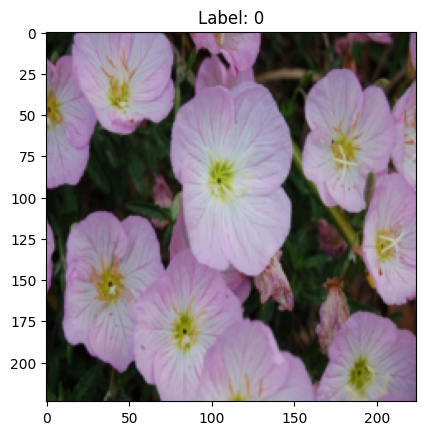

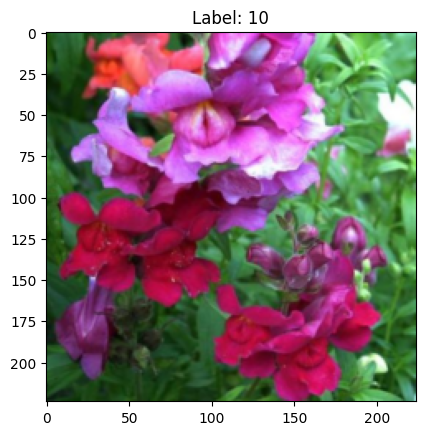

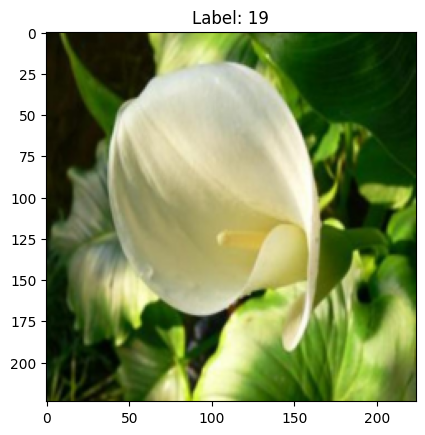

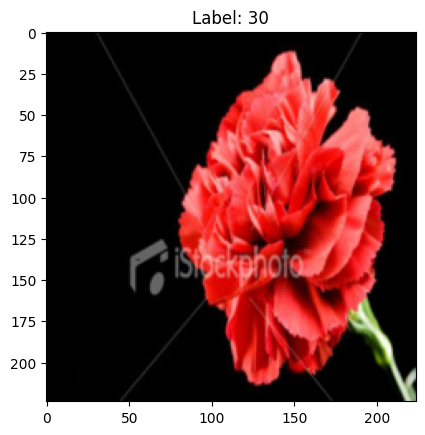

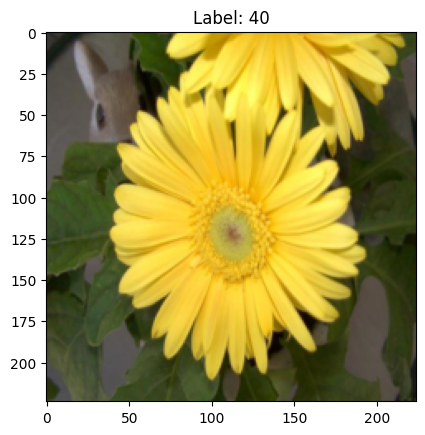

In [6]:
for i in range(5):  # Take example image 0,100,200,300,400
    index = i*100
    curr_f = train_nn[index][0]

    #reshape each data form (3, 224, 224) to (224, 224, 3) to plot img correctly
    reshaped_curr_f = curr_f.permute(1, 2, 0)

    curr_lab = train_nn[index][1]
    plt.title("Label: %d" % curr_lab)
    plt.imshow(reshaped_curr_f)
    plt.pause(0.5)

### **Reflection Question (1a):**
In the data exploration stage, what is the purpose of "***assert isinstance(train_nn, Dataset)***"?


**Your Answer:**

It checks that `train_nn` is a PyTorch Dataset. If not, an AssertionError stops execution early, before the DataLoader is used.

## **Part 2: Self-defined CNN (8 points)**

In this section, you will define your own CNN (convolutional neural network) to classify the Oxford flowers.

To build a neural network using `torch`, we build a class that carries out the functions of the model, define an optimizer, and iterate through a few key steps.

Here, we can make use of [`torch.nn.Sequential`](https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html) to define the layers in order.

### Instructions

One suggestion is that you build a model with the following architecture, although you are free to try others as well with the same idea:

1.) Convolution with 3x3 kernel, input shape is the image shape. Make use of [`torch.nn.Conv2d`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d), followed by [`torch.nn.ReLU`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU) and [`torch.nn.MaxPool2d`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d) with `kernel_size` 2 and `stride` 2

2.) Repeat step 1 (or a couple times), being careful about input shape

3.) Convolution with 3x3 kernel, input shape is the image shape. Make use of [`torch.nn.Conv2d`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d), followed by [`torch.nn.ReLU`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU) and [`torch.nn.Flatten`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten)

4.) Fully connected layer using [`torch.nn.Linear`](https://pytorch.org/docs/stable/generated/torch.nn.Linear) and [`torch.nn.ReLU`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU)

5.)[`torch.nn.Dropout`](https://pytorch.org/docs/stable/generated/torch.nn.Dropout)

6.) Linear layer returning us to number of classes (102)

7.) [`nothing`] or [`torch.nn.LogSoftmax`](https://pytorch.org/docs/stable/generated/torch.nn.LogSoftmax) for the output layer. Remember now that depending on which of these you use, you will need either [`criterion = nn.CrossEntropyLoss()`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss) or [`criterion = nn.NLLLoss()`](https://pytorch.org/docs/stable/generated/torch.nn.NLLLoss) in training. Use raw logits with `nn.CrossEntropyLoss()`, or `nn.LogSoftmax(dim=1)` with `nn.NLLLoss()`. For predicted labels, use `output.argmax(dim=1)` directly; softmax is needed only if you want class probabilities.

After fitting the model, please test the accuracy of the prediction on the test set.

In this stage, we do not ask for a great performance (you should have 'some' predictive performance though). But please ensure that you obtain a trainable model with no programming bugs. You may find it helpful to print the training progress bar or epoch.

**Grading:** model definition (3 points); loss, optimizer, scheduler, and training (3 points); test evaluation (1 point); the two reflection questions (1 point total).


In [7]:
# Step 1: Model definition
# Use a nn.Sequential model for deining your own CNN

########## Your code here ##########
# Define the model using nn.Sequential, naming it model






model = nn.Sequential(
    nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
    nn.Linear(64, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 102)
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print("Training device:", device)


Training device: cuda


In [8]:
# Optional: print a summary of your model
# from torchsummary import summary

# Assuming your model is defined, you can print the summary
# summary(model, (3, 224, 224))  # Assuming input size is (3, 224, 224)

### Instructions:

Here we will prepare ourselves for training.

We need to define a few things before running our training loop, namely the `DataLoader`, `criterion`, [`optimizer`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html), and [`lr_scheduler`](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.StepLR.html).

In [9]:
# Step 2: Model compilation
# Be sure to specify the optimizer, loss and metric as required


# Assuming you have a PyTorch model named 'model'
train_loader_nn = DataLoader(train_nn, batch_size=32, shuffle=True)


# Define your loss function, naming it 'criterion'
########## Your code here ##########


# Define your optimizer, 'optimizer' (Adam is suggested)
########## Your code here ##########


# Learning rate scheduler, 'lr_scheduler' (StepLR is suggested)
########## Your code here ##########



criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)


### Instructions:

Fill in necessary blanks in the training loop, with the provided guidance

In [10]:
# Step 3: Model fitting
# Use the prepared training data to fit your CN
# Training loop
epochs = 15  # Set the number of training epochs
# Total number of data points in the dataset (number of points per epoch)
n_train = len(train_loader_nn.dataset)

print("start to train")
for epoch in range(epochs):
    #print("epoch " + str(epoch))
    model.train()
    total_accuracy = 0.0
    total_loss = 0.0

    for batch in train_loader_nn:
        inputs, labels = (item.to(device) for item in batch)
        # zero the gradient, calculate outputs, calculate loss,
        # backpropagate, and take a step
        # Complete the optimization steps described above.
        ########## YOUR CODE HERE ###########
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()




        # Calculate accuracy for this batch
        predicted_classes = outputs.argmax(dim=1)
        batch_accuracy = (predicted_classes == labels).float().sum()
        total_accuracy += batch_accuracy.item()
        total_loss += loss.item() * len(labels)


    # Calculate the average accuracy for the entire epoch
    average_accuracy = total_accuracy / n_train
    average_loss = total_loss / n_train
    # Take a step in learning rate with lr_scheduler
    ############# YOUR CODE HERE ############### Adjust learning rate
    lr_scheduler.step()

    print(f" Epoch {epoch + 1}/{epochs}, Loss: {average_loss:.3f}, Accuracy: {average_accuracy * 100:.2f}%")
    #print("len train_loader is " + str(len(train_loader_nn)))


start to train


 Epoch 1/15, Loss: 4.632, Accuracy: 0.69%


 Epoch 2/15, Loss: 4.627, Accuracy: 0.78%


 Epoch 3/15, Loss: 4.566, Accuracy: 1.86%


 Epoch 4/15, Loss: 4.366, Accuracy: 1.76%


 Epoch 5/15, Loss: 4.254, Accuracy: 1.37%


... (6 outputs left out)

 Epoch 12/15, Loss: 3.932, Accuracy: 4.02%


 Epoch 13/15, Loss: 3.905, Accuracy: 5.39%


 Epoch 14/15, Loss: 3.858, Accuracy: 5.00%


 Epoch 15/15, Loss: 3.859, Accuracy: 5.49%


In [11]:
# Step 4: Model evaluation
test_dataloader_nn = DataLoader(test_nn, batch_size=32, shuffle=True)
n_test = len(test_dataloader_nn.dataset)  # Total number of test data points

model.eval()  # Set the model to evaluation mode

with torch.no_grad():  # Disable gradient calculation during evaluation
    test_total_accuracy = 0.0
    test_total_loss = 0.0

    # Iterate through the test dataset
    for test_batch in test_dataloader_nn:
        test_inputs, test_labels = (item.to(device) for item in test_batch)

        # Forward pass
        test_outputs = model(test_inputs)

        # Calculate the loss for the current batch
        test_loss = criterion(test_outputs, test_labels)

        # Accumulate the total loss (convert average loss to sum)
        test_total_loss += test_loss.item() * len(test_labels)

        # Calculate the accuracy for the current batch
        test_predicted_classes = test_outputs.argmax(dim=1)
        test_batch_accuracy = (test_predicted_classes == test_labels).float().sum()
        test_total_accuracy += test_batch_accuracy

    # Compute the average accuracy over the entire test set
    test_average_accuracy = test_total_accuracy / n_test

    # Compute the average loss over the entire test set
    test_average_loss = test_total_loss / n_test

    # Print results
    print(f"Test Loss: {test_average_loss:.4f}   Test Accuracy: {test_average_accuracy.item() * 100:.2f}%")


Test Loss: 3.9678   Test Accuracy: 5.81%


### **Reflection Questions:**

(1) How did you choose your network structure? \\
(2) Which optimizer did you use? Why? \\

**Your Answer:**






(1) I used three convolution/ReLU/pooling blocks to learn increasingly complex image features while reducing spatial size. Global average pooling keeps the classifier small, and dropout reduces overfitting on the small training set.

(2) I used Adam because its adaptive step sizes provide a practical baseline for training from scratch.


## **Part 3: Transfer Learning Using a Pretrained Model (9 points)**

Use MobileNetV2 pretrained on ImageNet, freeze its pretrained parameters, and train a new classifier for the 102 flower classes.

**Grading:** frozen pretrained parameters and new classifier (3 points); classifier training (2 points); test evaluation (1 point); the five reflection questions and final open-ended observation (3 points total).


### (1) Freeze the pretrained parameters and train a new classifier.


In [12]:
import torchvision

# Load the pre-trained MobileNetV2 model
MobileNetV2 = torchvision.models.mobilenet_v2(pretrained=True)
MobileNetV2.classifier = nn.Identity()  # Remove the classifier layers

# Set the model to evaluation mode
MobileNetV2.eval()

C:\Users\Administrator\AppData\Roaming\Python\Python314\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Administrator\AppData\Roaming\Python\Python314\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

Now you can go through the same steps to build and train the transfer learning model.

### Instructions:
Within the `model_transfer = nn.Sequential()` call, add an Adaptive Average Pooling layer with [`nn.AdaptiveAvgPool2d()`](https://pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d), then perform flattening and apply a linear layer as you should be familiar with from earlier.

Use raw logits with `nn.CrossEntropyLoss()`, or `nn.LogSoftmax(dim=1)` with `nn.NLLLoss()`. Predicted labels can be obtained with `argmax` without applying softmax. The pretrained parameters must remain fixed while the new classifier is trained.

In [13]:
# Step 1: Model definition
# Use a torch.nn Sequential model for defining the transfer learning model (frozen pretrained parameters)

# Set MobileNetV2 parameters to non-trainable
for param in MobileNetV2.parameters():
    param.requires_grad = False

# Use a custom reshape layer
class ReshapeLayer(nn.Module):
    def forward(self, x):
        return x.view(x.size(0), x.size(1), 1, 1)

# Create a Sequential model in PyTorch
model_transfer = nn.Sequential(
    MobileNetV2,
    ReshapeLayer(),  # Reshape to [batch_size, num_channels, 1, 1]

########## Your code here ##########
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten(),
    nn.Linear(1280, 102),




)
model_transfer = model_transfer.to(device)


In [14]:
# define batch size here
batch_size = 32
input_tensor = torch.randn([batch_size, 3, 224, 224], device=device)

# visualize the model graphical structure
#Iterate through the model and print the dimensions at each layer
for layer in model_transfer:
    input_tensor = layer(input_tensor)
    print(f"Layer: {layer.__class__.__name__}, Output Shape: {input_tensor.shape}")

Layer: MobileNetV2, Output Shape: torch.Size([32, 1280])
Layer: ReshapeLayer, Output Shape: torch.Size([32, 1280, 1, 1])
Layer: AdaptiveAvgPool2d, Output Shape: torch.Size([32, 1280, 1, 1])
Layer: Flatten, Output Shape: torch.Size([32, 1280])
Layer: Linear, Output Shape: torch.Size([32, 102])


In [15]:
#print(model_transfer)

### Instructions:

As before, write code to define your `optimizer`, `DataLoader`, `loss (criterion)`, and `lr_scheduler`.

Then, write a training loop.

Your code here should look similar to earlier in the assignment, outside of choosing hyperparameters, names, and possibly choice of loss.

In [16]:
# Step 2: Prepare for training
########## Your code here ##########
torch.manual_seed(42)
train_loader_transfer = DataLoader(train_nn, batch_size=32, shuffle=True)
criterion = nn.CrossEntropyLoss()
optimizer_transfer = torch.optim.Adam(model_transfer[-1].parameters(), lr=0.001)
scheduler_transfer = torch.optim.lr_scheduler.StepLR(optimizer_transfer, step_size=3, gamma=0.5)

# Training loop
epochs = 5
########## Your code here ##########
for epoch in range(epochs):
    model_transfer.train()
    MobileNetV2.eval()  # Keep frozen batch-normalization statistics fixed.
    total_loss, correct = 0.0, 0
    for inputs, labels in train_loader_transfer:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_transfer.zero_grad()
        outputs = model_transfer(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_transfer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
    scheduler_transfer.step()
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {total_loss / len(train_nn):.3f}, Accuracy: {100 * correct / len(train_nn):.2f}%")


Epoch 1/5, Loss: 4.344, Accuracy: 14.61%


Epoch 2/5, Loss: 2.607, Accuracy: 61.37%


Epoch 3/5, Loss: 1.677, Accuracy: 79.41%


Epoch 4/5, Loss: 1.184, Accuracy: 91.08%


Epoch 5/5, Loss: 0.986, Accuracy: 94.22%


In [17]:
# Step 3: Model evaluation
# Use the prepared testing data to evaluate the transfer learning model

#test_dataloader_nn = DataLoader(test_nn, batch_size=32, shuffle=True)

print("model_transfer")
model_transfer.eval()  # Set the model to evaluation mode
with torch.no_grad():

    test_total_accuracy = 0.0
    test_total_loss = 0.0  # Reset total loss at the beginning of each epoch

    for test_batch in test_dataloader_nn:
        test_inputs, test_labels = (item.to(device) for item in test_batch)
        test_outputs = model_transfer(test_inputs)
        test_loss = criterion(test_outputs, test_labels)
        # Accumulate the total loss (convert average loss to sum)
        test_total_loss += test_loss.item() * len(test_labels)
        _, test_predicted = torch.max(test_outputs, 1)  # Get the predicted class
        test_batch_accuracy = (test_predicted == test_labels).float().sum()
        test_total_accuracy += test_batch_accuracy.item()


    # Compute the average accuracy over the entire test set
    test_average_accuracy = test_total_accuracy / n_test

    # Compute the average loss over the entire test set
    test_average_loss = test_total_loss / n_test

    # Print results
    print(f"Test Loss: {test_average_loss:.3f}   Test Accuracy: {test_average_accuracy * 100:.2f}%")

model_transfer


Test Loss: 1.634   Test Accuracy: 74.16%


### (2) Try other hyperparameter settings using validation data. (Optional, ungraded)

If you complete this optional experiment, load the separate official validation split using `Flowers102(root='', split="val", download=True, transform=transform)`. Select settings on validation data before final test evaluation; do not tune on the test results.


In [18]:
########## Your code here ##########




### **Reflection Questions:**

(1) Briefly explain the network structure of MobileNet and how is it different from other models? \\
(2) In your experiment, which parameter(s) is the network most sensitive to? Can you briefly reason why? \\
(3) What are some pros and cons of doing transfer learning? \\
(4) What is a batch? How does the batch size affect the training process? \\
(5) What is an epoch during the training process?

**Your Answer:**




1. MobileNetV2 uses depthwise separable convolutions and inverted residual blocks with linear bottlenecks. These reduce computation and parameters compared with many conventional convolutions.

2. No systematic hyperparameter comparison was performed, so the most sensitive parameter cannot be determined from this run. The learning rate is a plausible candidate because it controls update size; this requires validation experiments.

3. Transfer learning can converge faster and need less labeled data, but pretrained features may not match the target domain, and the model can inherit biases from pretraining.

4. A batch is a subset of training examples used for one update. Larger batches typically use more memory and give less noisy gradients; smaller ones give noisier updates and more updates per epoch.

5. An epoch is one complete pass through the training dataset.


**Further reflection:** Describe any observation you find interesting from the above experiment (Open-ended).

**Your Answer:**




The pretrained network starts with features learned from a large image dataset, whereas the custom CNN must learn features from the relatively small flower training split. Comparing their test results illustrates how this affects generalization.
